<a href="https://colab.research.google.com/github/PrasastiBaitharu/Frontend-Project/blob/main/Copy_of_YBI_AI_Student_Career_Recommendation_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI-Based Student Career Prediction and Skill Recommendation System

### YBI Foundation Internship — Self Project

## Project Overview

This project aims to develop a machine learning-based system that analyzes student academic information and extracurricular/academic activity data to predict suitable career categories.

After predicting a career category, the system uses career-related information to identify relevant skills and activities that can help the student understand areas for further development.

The project follows the complete machine learning workflow:

- Data collection
- Data understanding
- Data preprocessing
- Exploratory Data Analysis
- Feature engineering
- Model training
- Model evaluation
- Model comparison
- Experimentation
- Career prediction
- Skill recommendation

## Problem Statement

Students participate in different academic and extracurricular activities, but it can be difficult to understand how their interests and performance relate to possible career paths.

This project explores whether machine learning can use student and activity-related information to predict a suitable career category and provide supporting skill recommendations.

## Objectives

1. Understand and analyze student and activity data.
2. Clean and preprocess the datasets.
3. Create meaningful features from student activities.
4. Build machine learning classification models.
5. Compare multiple classification algorithms.
6. Perform experiments by changing relevant parameters.
7. Evaluate model performance using appropriate metrics.
8. Select a final model based on experimental results.
9. Predict career categories for students.
10. Provide career-related skill recommendations.

In [ ]:
!git clone https://github.com/narendrar-133/Student-Career-Prediction-System.git

Cloning into 'Student-Career-Prediction-System'...
remote: Enumerating objects: 44, done.
remote: Counting objects: 100% (44/44), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 44 (delta 12), reused 4 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (44/44), 156.66 KiB | 2.53 MiB/s, done.
Resolving deltas: 100% (12/12), done.


In [ ]:
import pandas as pd

base_path = "Student-Career-Prediction-System/dataset/"

student_df = pd.read_csv(base_path + "student.csv")
activity_df = pd.read_csv(base_path + "activity.csv")
career_df = pd.read_csv(base_path + "career.csv")

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
print("Student Dataset:", student_df.shape)
print("Activity Dataset:", activity_df.shape)
print("Career Dataset:", career_df.shape)

Student Dataset: (1000, 8)
Activity Dataset: (3496, 8)
Career Dataset: (8, 6)


In [ ]:
student_df.head()

,student_id,name,dob,class,board,school,actual_career_id,predicted_career_id
0,1,Katelyn Roberts,2010-03-19,9,ICSE,Turner Group,1,NaN
1,2,Kayla Lucas,2010-07-02,8,ICSE,"Gibson, Smith and Torres",3,NaN
2,3,Rhonda Merritt,2009-10-27,11,ICSE,"Williams, Hull and Anderson",4,NaN
3,4,Erik Chavez,2009-04-29,12,CBSE,Daniels Group,4,NaN
4,5,Megan Anderson,2007-07-28,9,State Board,Ray Ltd,1,NaN


In [ ]:
student_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   student_id           1000 non-null   int64  
 1   name                 1000 non-null   object 
 2   dob                  1000 non-null   object 
 3   class                1000 non-null   int64  
 4   board                1000 non-null   object 
 5   school               1000 non-null   object 
 6   actual_career_id     1000 non-null   int64  
 7   predicted_career_id  0 non-null      float64
dtypes: float64(1), int64(3), object(4)
memory usage: 62.6+ KB


In [ ]:
student_df.describe(include="all")

,student_id,name,dob,class,board,school,actual_career_id,predicted_career_id
count,1000.000000,1000,1000,1000.000000,1000,1000,1000.000000,0.0
unique,NaN,994,713,NaN,3,973,NaN,NaN
top,NaN,Matthew Johnson,2007-07-27,NaN,ICSE,Wilson and Sons,NaN,NaN
freq,NaN,2,5,NaN,334,4,NaN,NaN
mean,500.500000,NaN,NaN,10.004000,NaN,NaN,3.549000,NaN
std,288.819436,NaN,NaN,1.392093,NaN,NaN,2.260688,NaN
min,1.000000,NaN,NaN,8.000000,NaN,NaN,1.000000,NaN
25%,250.750000,NaN,NaN,9.000000,NaN,NaN,2.000000,NaN
50%,500.500000,NaN,NaN,10.000000,NaN,NaN,3.000000,NaN
75%,750.250000,NaN,NaN,11.000000,NaN,NaN,5.000000,NaN


In [ ]:
activity_df.head()

,activity_id,student_id,activity_name,category,level,participation,score,year
0,1,1,Physics,Academics,Beginner,Occasional,96,2024
1,2,1,Coding,Academics,Advanced,Regular,95,2023
2,3,1,Economics,Academics,Beginner,Regular,71,2022
3,4,1,Music,Extra-curricular,Beginner,Regular,57,2021
4,5,1,Biology,Academics,Advanced,Occasional,66,2022


In [ ]:
activity_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3496 entries, 0 to 3495
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   activity_id    3496 non-null   int64 
 1   student_id     3496 non-null   int64 
 2   activity_name  3496 non-null   object
 3   category       3496 non-null   object
 4   level          3496 non-null   object
 5   participation  3496 non-null   object
 6   score          3496 non-null   int64 
 7   year           3496 non-null   int64 
dtypes: int64(4), object(4)
memory usage: 218.6+ KB


In [ ]:
activity_df.describe(include="all")

,activity_id,student_id,activity_name,category,level,participation,score,year
count,3496.000000,3496.000000,3496,3496,3496,3496,3496.000000,3496.000000
unique,NaN,NaN,11,3,3,2,NaN,NaN
top,NaN,NaN,Music,Academics,Advanced,Occasional,NaN,NaN
freq,NaN,NaN,335,1573,1215,1775,NaN,NaN
mean,1748.500000,496.656178,NaN,NaN,NaN,NaN,69.188501,2023.005149
std,1009.352598,290.150309,NaN,NaN,NaN,NaN,15.549310,1.394441
min,1.000000,1.000000,NaN,NaN,NaN,NaN,40.000000,2021.000000
25%,874.750000,240.750000,NaN,NaN,NaN,NaN,56.000000,2022.000000
50%,1748.500000,495.500000,NaN,NaN,NaN,NaN,69.000000,2023.000000
75%,2622.250000,749.000000,NaN,NaN,NaN,NaN,82.000000,2024.000000


In [ ]:
career_df.head()

,career_id,career_name,career_type,threshold,recommended_activities,required_skills
0,1,Science,Stream,75,"Coding,Mathematics,Biology","Logical thinking,Analysis"
1,2,Commerce,Stream,65,"Economics,Debate,Mathematics","Numerical skills,Communication"
2,3,Arts,Stream,55,"Art,Music,Debate","Creativity,Expression"
3,4,Engineer,Profession,80,"Coding,Mathematics,Physics","Problem solving,Programming"
4,5,Doctor,Profession,85,"Biology,Chemistry","Observation,Discipline"


In [ ]:
career_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   career_id               8 non-null      int64 
 1   career_name             8 non-null      object
 2   career_type             8 non-null      object
 3   threshold               8 non-null      int64 
 4   recommended_activities  8 non-null      object
 5   required_skills         8 non-null      object
dtypes: int64(2), object(4)
memory usage: 516.0+ bytes


In [ ]:
print("===== STUDENT MISSING VALUES =====")
print(student_df.isnull().sum())

print("\n===== ACTIVITY MISSING VALUES =====")
print(activity_df.isnull().sum())

print("\n===== CAREER MISSING VALUES =====")
print(career_df.isnull().sum())

===== STUDENT MISSING VALUES =====
student_id                0
name                      0
dob                       0
class                     0
board                     0
school                    0
actual_career_id          0
predicted_career_id    1000
dtype: int64

===== ACTIVITY MISSING VALUES =====
activity_id      0
student_id       0
activity_name    0
category         0
level            0
participation    0
score            0
year             0
dtype: int64

===== CAREER MISSING VALUES =====
career_id                 0
career_name               0
career_type               0
threshold                 0
recommended_activities    0
required_skills           0
dtype: int64


In [ ]:
print("Student duplicates:", student_df.duplicated().sum())
print("Activity duplicates:", activity_df.duplicated().sum())
print("Career duplicates:", career_df.duplicated().sum())

Student duplicates: 0
Activity duplicates: 0
Career duplicates: 0


In [ ]:
student_df["actual_career_id"].value_counts().sort_index()

,count
actual_career_id,
1,215
2,198
3,198
4,82
5,63
6,87
7,77
8,80


In [ ]:
career_df[["career_id", "career_name", "career_type"]]

,career_id,career_name,career_type
0,1,Science,Stream
1,2,Commerce,Stream
2,3,Arts,Stream
3,4,Engineer,Profession
4,5,Doctor,Profession
5,6,Chartered Accountant,Profession
6,7,Artist,Profession
7,8,Sports Professional,Profession


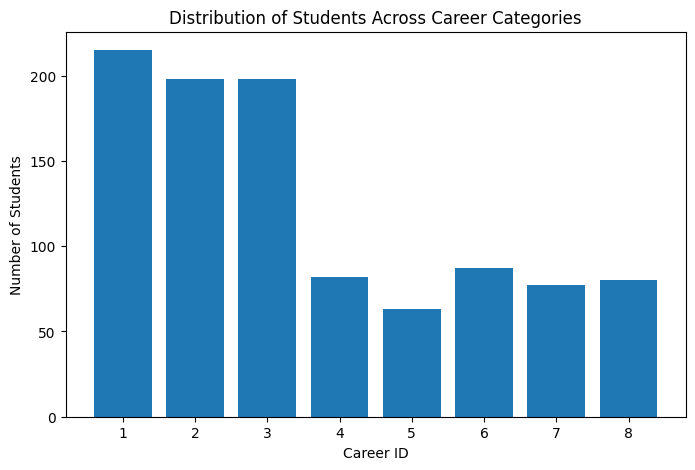

In [ ]:
career_counts = student_df["actual_career_id"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    career_counts.index.astype(str),
    career_counts.values
)

plt.title("Distribution of Students Across Career Categories")
plt.xlabel("Career ID")
plt.ylabel("Number of Students")

plt.show()

In [ ]:
activity_df["category"].value_counts()

,count
category,
Academics,1573
Extra-curricular,983
Sports,940


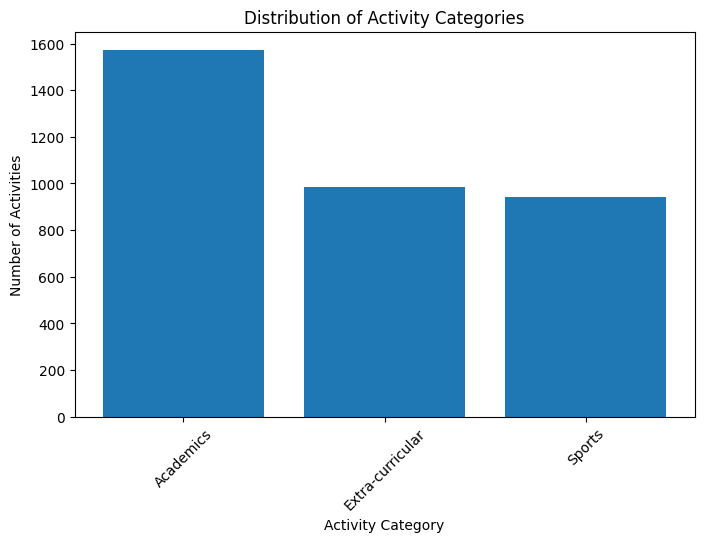

In [ ]:
category_counts = activity_df["category"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    category_counts.index,
    category_counts.values
)

plt.title("Distribution of Activity Categories")
plt.xlabel("Activity Category")
plt.ylabel("Number of Activities")

plt.xticks(rotation=45)

plt.show()

In [ ]:
activity_df["level"].value_counts()

,count
level,
Advanced,1215
Intermediate,1153
Beginner,1128


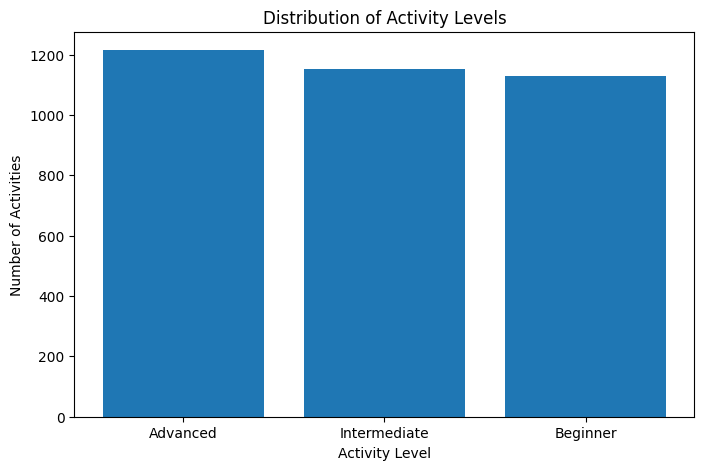

In [ ]:
level_counts = activity_df["level"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    level_counts.index,
    level_counts.values
)

plt.title("Distribution of Activity Levels")
plt.xlabel("Activity Level")
plt.ylabel("Number of Activities")

plt.show()

In [ ]:
activity_df["participation"].value_counts()

,count
participation,
Occasional,1775
Regular,1721


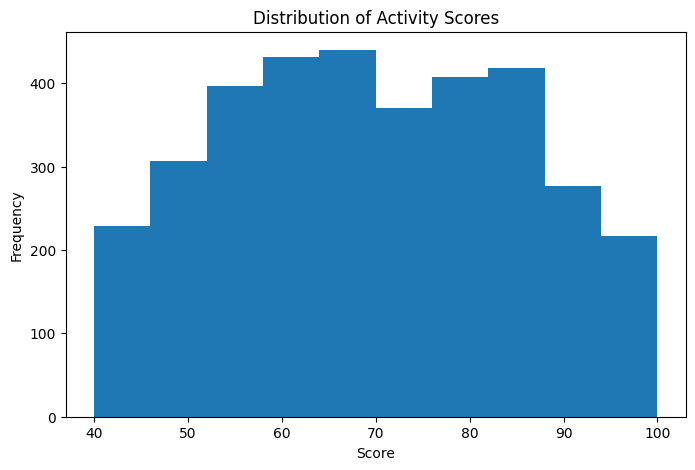

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    activity_df["score"],
    bins=10
)

plt.title("Distribution of Activity Scores")
plt.xlabel("Score")
plt.ylabel("Frequency")

plt.show()

In [ ]:
student = student_df.copy()
activity = activity_df.copy()
career = career_df.copy()

print("Copies created successfully!")

Copies created successfully!


In [ ]:
student["dob"] = pd.to_datetime(student["dob"])

reference_date = pd.Timestamp("2026-01-01")

student["age"] = (
    (reference_date - student["dob"]).dt.days / 365.25
).astype(int)

student[["student_id", "dob", "age"]].head()

,student_id,dob,age
0,1,2010-03-19,15
1,2,2010-07-02,15
2,3,2009-10-27,16
3,4,2009-04-29,16
4,5,2007-07-28,18


In [ ]:
student_features = student.drop(
    columns=[
        "name",
        "dob",
        "school",
        "actual_career_id",
        "predicted_career_id"
    ]
)

student_features.head()

,student_id,class,board,age
0,1,9,ICSE,15
1,2,8,ICSE,15
2,3,11,ICSE,16
3,4,12,CBSE,16
4,5,9,State Board,18


In [ ]:
activity_count = (
    activity.groupby("student_id")
    .size()
    .reset_index(name="total_activities")
)

activity_count.head()

,student_id,total_activities
0,1,5
1,2,2
2,3,5
3,4,4
4,5,5


In [ ]:
avg_score = (
    activity.groupby("student_id")["score"]
    .mean()
    .reset_index(name="average_score")
)

avg_score.head()

,student_id,average_score
0,1,77.00
1,2,57.50
2,3,64.00
3,4,70.25
4,5,68.00


In [ ]:
max_score = (
    activity.groupby("student_id")["score"]
    .max()
    .reset_index(name="max_score")
)

max_score.head()

,student_id,max_score
0,1,96
1,2,64
2,3,79
3,4,82
4,5,81


In [ ]:
min_score = (
    activity.groupby("student_id")["score"]
    .min()
    .reset_index(name="min_score")
)

In [ ]:
category_features = pd.crosstab(
    activity["student_id"],
    activity["category"]
).reset_index()

category_features.head()

category,student_id,Academics,Extra-curricular,Sports
0,1,4,1,0
1,2,2,0,0
2,3,1,2,2
3,4,1,1,2
4,5,2,1,2


In [ ]:
level_features = pd.crosstab(
    activity["student_id"],
    activity["level"]
).reset_index()

level_features.head()

level,student_id,Advanced,Beginner,Intermediate
0,1,2,3,0
1,2,0,0,2
2,3,1,3,1
3,4,1,3,0
4,5,1,2,2


In [ ]:
participation_features = pd.crosstab(
    activity["student_id"],
    activity["participation"]
).reset_index()

participation_features.head()

participation,student_id,Occasional,Regular
0,1,2,3
1,2,1,1
2,3,2,3
3,4,1,3
4,5,3,2


In [ ]:
activity_features = activity_count.copy()

activity_features = activity_features.merge(
    avg_score,
    on="student_id",
    how="left"
)

activity_features = activity_features.merge(
    max_score,
    on="student_id",
    how="left"
)

activity_features = activity_features.merge(
    min_score,
    on="student_id",
    how="left"
)

activity_features = activity_features.merge(
    category_features,
    on="student_id",
    how="left"
)

activity_features = activity_features.merge(
    level_features,
    on="student_id",
    how="left"
)

activity_features = activity_features.merge(
    participation_features,
    on="student_id",
    how="left"
)

activity_features.head()

,student_id,total_activities,average_score,max_score,min_score,Academics,Extra-curricular,Sports,Advanced,Beginner,Intermediate,Occasional,Regular
0,1,5,77.00,96,57,4,1,0,2,3,0,2,3
1,2,2,57.50,64,51,2,0,0,0,0,2,1,1
2,3,5,64.00,79,50,1,2,2,1,3,1,2,3
3,4,4,70.25,82,54,1,1,2,1,3,0,1,3
4,5,5,68.00,81,55,2,1,2,1,2,2,3,2


In [ ]:
print("Activity feature shape:", activity_features.shape)

print("\nActivity feature columns:")
print(activity_features.columns.tolist())

Activity feature shape: (1000, 13)

Activity feature columns:
['student_id', 'total_activities', 'average_score', 'max_score', 'min_score', 'Academics', 'Extra-curricular', 'Sports', 'Advanced', 'Beginner', 'Intermediate', 'Occasional', 'Regular']


In [ ]:
ml_data = student_features.merge(
    activity_features,
    on="student_id",
    how="left"
)

In [ ]:
print("ML dataset shape:", ml_data.shape)

ml_data.head()

ML dataset shape: (1000, 16)


,student_id,class,board,age,total_activities,average_score,max_score,min_score,Academics,Extra-curricular,Sports,Advanced,Beginner,Intermediate,Occasional,Regular
0,1,9,ICSE,15,5,77.00,96,57,4,1,0,2,3,0,2,3
1,2,8,ICSE,15,2,57.50,64,51,2,0,0,0,0,2,1,1
2,3,11,ICSE,16,5,64.00,79,50,1,2,2,1,3,1,2,3
3,4,12,CBSE,16,4,70.25,82,54,1,1,2,1,3,0,1,3
4,5,9,State Board,18,5,68.00,81,55,2,1,2,1,2,2,3,2


In [ ]:
ml_data = ml_data.merge(
    student[["student_id", "actual_career_id"]],
    on="student_id",
    how="left"
)

In [ ]:
ml_data.head()

,student_id,class,board,age,total_activities,average_score,max_score,min_score,Academics,Extra-curricular,Sports,Advanced,Beginner,Intermediate,Occasional,Regular,actual_career_id
0,1,9,ICSE,15,5,77.00,96,57,4,1,0,2,3,0,2,3,1
1,2,8,ICSE,15,2,57.50,64,51,2,0,0,0,0,2,1,1,3
2,3,11,ICSE,16,5,64.00,79,50,1,2,2,1,3,1,2,3,4
3,4,12,CBSE,16,4,70.25,82,54,1,1,2,1,3,0,1,3,4
4,5,9,State Board,18,5,68.00,81,55,2,1,2,1,2,2,3,2,1


In [ ]:
ml_data.isnull().sum()

,0
student_id,0
class,0
board,0
age,0
total_activities,0
average_score,0
max_score,0
min_score,0
Academics,0
Extra-curricular,0


In [ ]:
print("Rows:", ml_data.shape[0])
print("Columns:", ml_data.shape[1])

print("\nColumns:")
print(ml_data.columns.tolist())

Rows: 1000
Columns: 17

Columns:
['student_id', 'class', 'board', 'age', 'total_activities', 'average_score', 'max_score', 'min_score', 'Academics', 'Extra-curricular', 'Sports', 'Advanced', 'Beginner', 'Intermediate', 'Occasional', 'Regular', 'actual_career_id']


In [ ]:
ml_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        1000 non-null   int64  
 1   class             1000 non-null   int64  
 2   board             1000 non-null   object 
 3   age               1000 non-null   int64  
 4   total_activities  1000 non-null   int64  
 5   average_score     1000 non-null   float64
 6   max_score         1000 non-null   int64  
 7   min_score         1000 non-null   int64  
 8   Academics         1000 non-null   int64  
 9   Extra-curricular  1000 non-null   int64  
 10  Sports            1000 non-null   int64  
 11  Advanced          1000 non-null   int64  
 12  Beginner          1000 non-null   int64  
 13  Intermediate      1000 non-null   int64  
 14  Occasional        1000 non-null   int64  
 15  Regular           1000 non-null   int64  
 16  actual_career_id  1000 non-null   int64  
d

In [ ]:
ml_data.isnull().sum()

,0
student_id,0
class,0
board,0
age,0
total_activities,0
average_score,0
max_score,0
min_score,0
Academics,0
Extra-curricular,0


In [ ]:
print(ml_data.columns.tolist())

['student_id', 'class', 'board', 'age', 'total_activities', 'average_score', 'max_score', 'min_score', 'Academics', 'Extra-curricular', 'Sports', 'Advanced', 'Beginner', 'Intermediate', 'Occasional', 'Regular', 'actual_career_id']


In [ ]:
print("Career distribution:")
print(ml_data["actual_career_id"].value_counts().sort_index())

print("\nCareer mapping:")
print(career[["career_id", "career_name", "career_type"]])

Career distribution:
actual_career_id
1    215
2    198
3    198
4     82
5     63
6     87
7     77
8     80
Name: count, dtype: int64

Career mapping:
   career_id           career_name career_type
0          1               Science      Stream
1          2              Commerce      Stream
2          3                  Arts      Stream
3          4              Engineer  Profession
4          5                Doctor  Profession
5          6  Chartered Accountant  Profession
6          7                Artist  Profession
7          8   Sports Professional  Profession


In [ ]:
X = ml_data.drop(
    columns=["actual_career_id", "student_id"]
)

y = ml_data["actual_career_id"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

Feature shape: (1000, 15)
Target shape: (1000,)

Input features:
['class', 'board', 'age', 'total_activities', 'average_score', 'max_score', 'min_score', 'Academics', 'Extra-curricular', 'Sports', 'Advanced', 'Beginner', 'Intermediate', 'Occasional', 'Regular']


In [ ]:
X = pd.get_dummies(
    X,
    columns=["board"],
    dtype=int
)

print("Features after encoding:", X.shape)
print(X.head())

Features after encoding: (1000, 17)
   class  age  total_activities  average_score  max_score  min_score  \
0      9   15                 5          77.00         96         57   
1      8   15                 2          57.50         64         51   
2     11   16                 5          64.00         79         50   
3     12   16                 4          70.25         82         54   
4      9   18                 5          68.00         81         55   

   Academics  Extra-curricular  Sports  Advanced  Beginner  Intermediate  \
0          4                 1       0         2         3             0   
1          2                 0       0         0         0             2   
2          1                 2       2         1         3             1   
3          1                 1       2         1         3             0   
4          2                 1       2         1         2             2   

   Occasional  Regular  board_CBSE  board_ICSE  board_State Board  
0     

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training students:", len(y_train))
print("Testing students:", len(y_test))

Training features: (800, 17)
Testing features: (200, 17)
Training students: 800
Testing students: 200


In [ ]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

decision_tree.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [ ]:
y_pred_dt = decision_tree.predict(X_test)

print("Actual career IDs:")
print(y_test.head(10).tolist())

print("\nPredicted career IDs:")
print(y_pred_dt[:10].tolist())

Actual career IDs:
[3, 1, 2, 2, 4, 1, 3, 5, 3, 8]

Predicted career IDs:
[3, 1, 3, 2, 8, 3, 2, 8, 2, 7]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print(f"Decision Tree Accuracy: {accuracy_dt:.2%}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_dt,
        zero_division=0
    )
)

Decision Tree Accuracy: 31.00%

Classification Report:
              precision    recall  f1-score   support

           1       0.45      0.42      0.43        43
           2       0.31      0.25      0.28        40
           3       0.33      0.42      0.37        40
           4       0.20      0.19      0.19        16
           5       0.25      0.08      0.12        13
           6       0.17      0.29      0.22        17
           7       0.40      0.13      0.20        15
           8       0.25      0.38      0.30        16

    accuracy                           0.31       200
   macro avg       0.30      0.27      0.26       200
weighted avg       0.32      0.31      0.30       200



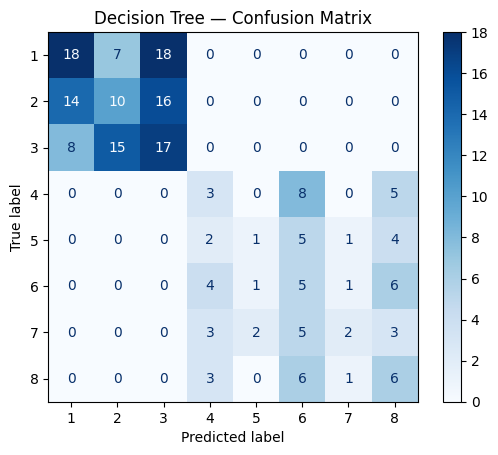

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    decision_tree,
    X_test,
    y_test,
    cmap="Blues"
)

plt.title("Decision Tree — Confusion Matrix")
plt.show()

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

logistic_model.fit(X_train, y_train)

y_pred_lr = logistic_model.predict(X_test)

print("Logistic Regression Accuracy:",
      f"{accuracy_score(y_test, y_pred_lr):.2%}")

print("Macro F1-score:",
      f"{f1_score(y_test, y_pred_lr, average='macro', zero_division=0):.3f}")

Logistic Regression Accuracy: 30.50%
Macro F1-score: 0.253


In [ ]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

print("Random Forest Accuracy:",
      f"{accuracy_score(y_test, y_pred_rf):.2%}")

print("Macro F1-score:",
      f"{f1_score(y_test, y_pred_rf, average='macro', zero_division=0):.3f}")

Random Forest Accuracy: 30.00%
Macro F1-score: 0.245


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Macro F1": [
        f1_score(y_test, y_pred_dt, average="macro", zero_division=0),
        f1_score(y_test, y_pred_lr, average="macro", zero_division=0),
        f1_score(y_test, y_pred_rf, average="macro", zero_division=0)
    ],
    "Weighted F1": [
        f1_score(y_test, y_pred_dt, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_lr, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_rf, average="weighted", zero_division=0)
    ]
})

print(results.round(3).to_string(index=False))

              Model  Accuracy  Macro F1  Weighted F1
      Decision Tree     0.310     0.264        0.304
Logistic Regression     0.305     0.253        0.298
      Random Forest     0.300     0.245        0.298


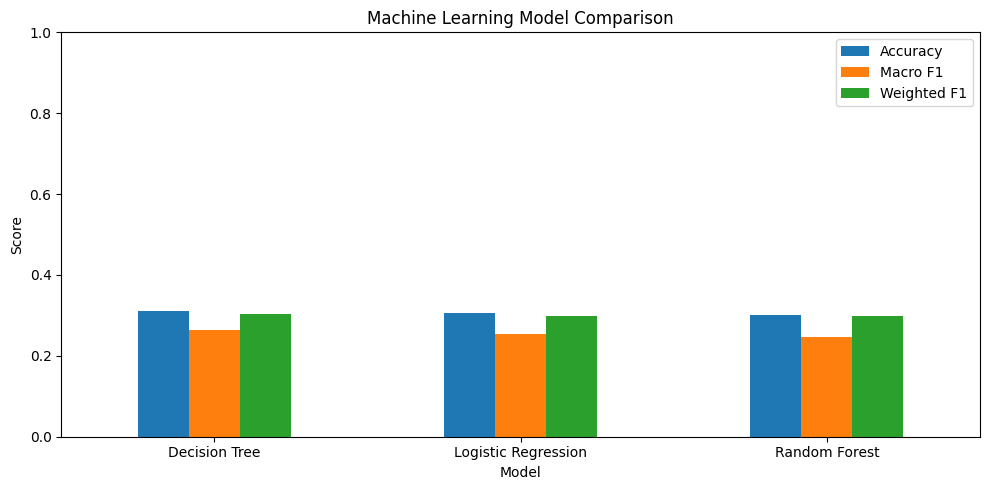

In [ ]:
results.plot(
    x="Model",
    y=["Accuracy", "Macro F1", "Weighted F1"],
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
!ls Student-Career-Prediction-System/code

predict_new_students.py  rule_labeling.py  train_model.py


In [ ]:
!find Student-Career-Prediction-System -type f

Student-Career-Prediction-System/.git/config
Student-Career-Prediction-System/.git/description
Student-Career-Prediction-System/.git/objects/pack/pack-30b66fc0fd0209a824c02e29f41067a9754c1414.pack
Student-Career-Prediction-System/.git/objects/pack/pack-30b66fc0fd0209a824c02e29f41067a9754c1414.rev
Student-Career-Prediction-System/.git/objects/pack/pack-30b66fc0fd0209a824c02e29f41067a9754c1414.idx
Student-Career-Prediction-System/.git/index
Student-Career-Prediction-System/.git/hooks/push-to-checkout.sample
Student-Career-Prediction-System/.git/hooks/pre-commit.sample
Student-Career-Prediction-System/.git/hooks/fsmonitor-watchman.sample
Student-Career-Prediction-System/.git/hooks/update.sample
Student-Career-Prediction-System/.git/hooks/pre-receive.sample
Student-Career-Prediction-System/.git/hooks/pre-applypatch.sample
Student-Career-Prediction-System/.git/hooks/pre-push.sample
Student-Career-Prediction-System/.git/hooks/sendemail-validate.sample
Student-Career-Prediction-System/.git/ho

In [ ]:
!cat Student-Career-Prediction-System/code/rule_labeling.py

import mysql.connector
import pandas as pd

# DB connection
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="user123",
    database="career_path_db"
)

print("Connected to database")

# Load features
df = pd.read_sql("SELECT * FROM student_features_v2", conn)

# Career mapping (update IDs if needed)
CAREER_MAP = {
    "Science": 1,
    "Commerce": 2,
    "Arts": 3,
    "Engineer": 4,
    "Doctor": 5,
    "CA": 6,
    "Artist": 7,
    "Sports Professional": 8
}

def assign_career(row):
    cls = row["class"]

    avg_ac = row["avg_academic_score"] or 0
    avg_sp = row["avg_sports_score"] or 0
    avg_ex = row["avg_extra_score"] or 0

    ac_cnt = row["academic_activity_count"]
    sp_cnt = row["sports_activity_count"]
    ex_cnt = row["extra_activity_count"]

    # -------- STREAM LOGIC (<=10) --------
    if cls <= 10:
        if avg_ac >= 75 and ac_cnt >= ex_cnt:
            return CAREER_MAP["Science"]

        elif avg_ex >= 70 and ex_cnt > ac_cn

In [ ]:
print(results.round(4).to_string(index=False))

              Model  Accuracy  Macro F1  Weighted F1
      Decision Tree     0.310    0.2642       0.3041
Logistic Regression     0.305    0.2529       0.2982
      Random Forest     0.300    0.2455       0.2976


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline Accuracy:",
      f"{accuracy_score(y_test, baseline_pred):.2%}")

print("Baseline Macro F1:",
      f"{f1_score(y_test, baseline_pred, average='macro', zero_division=0):.3f}")

Baseline Accuracy: 21.50%
Baseline Macro F1: 0.044


In [ ]:
print(activity["category"].value_counts())

category
Academics           1573
Extra-curricular     983
Sports               940
Name: count, dtype: int64


In [ ]:
# Calculate average scores for each activity category
category_avg = activity.pivot_table(
    index="student_id",
    columns="category",
    values="score",
    aggfunc="mean"
)

# Calculate activity counts for each category
category_count = activity.pivot_table(
    index="student_id",
    columns="category",
    values="activity_id",
    aggfunc="count"
)

# Rename columns
category_avg = category_avg.rename(columns={
    "Academics": "avg_academic_score",
    "Sports": "avg_sports_score",
    "Extra-curricular": "avg_extra_score"
})

category_count = category_count.rename(columns={
    "Academics": "academic_activity_count",
    "Sports": "sports_activity_count",
    "Extra-curricular": "extra_activity_count"
})

# Combine features
rule_features = category_avg.join(category_count, how="outer")

# Missing categories mean no recorded activity
rule_features = rule_features.fillna(0)

print(rule_features.head())

category    avg_academic_score  avg_extra_score  avg_sports_score  \
student_id                                                          
1                         82.0             57.0               0.0   
2                         57.5              0.0               0.0   
3                         58.0             70.0              61.0   
4                         82.0             54.0              72.5   
5                         59.5             68.0              76.5   

category    academic_activity_count  extra_activity_count  \
student_id                                                  
1                               4.0                   1.0   
2                               2.0                   0.0   
3                               1.0                   2.0   
4                               1.0                   1.0   
5                               2.0                   1.0   

category    sports_activity_count  
student_id                         
1               

In [ ]:
CAREER_MAP = {
    "Science": 1,
    "Commerce": 2,
    "Arts": 3,
    "Engineer": 4,
    "Doctor": 5,
    "CA": 6,
    "Artist": 7,
    "Sports Professional": 8
}

def assign_career(row):

    cls = row["class"]

    avg_ac = row["avg_academic_score"]
    avg_sp = row["avg_sports_score"]
    avg_ex = row["avg_extra_score"]

    ac_cnt = row["academic_activity_count"]
    sp_cnt = row["sports_activity_count"]
    ex_cnt = row["extra_activity_count"]

    if cls <= 10:

        if avg_ac >= 75 and ac_cnt >= ex_cnt:
            return CAREER_MAP["Science"]

        elif avg_ex >= 70 and ex_cnt > ac_cnt:
            return CAREER_MAP["Arts"]

        elif avg_ac >= 65 and avg_ex >= 60:
            return CAREER_MAP["Commerce"]

        elif avg_sp >= 70 and sp_cnt >= ac_cnt:
            return CAREER_MAP["Sports Professional"]

        else:
            return CAREER_MAP["Arts"]

    else:

        if avg_ac >= 80 and ac_cnt >= 3:
            return CAREER_MAP["Engineer"]

        elif avg_ac >= 75 and avg_ex >= 60:
            return CAREER_MAP["Doctor"]

        elif avg_ac >= 70 and ex_cnt >= 2:
            return CAREER_MAP["CA"]

        elif avg_ex >= 75 and ex_cnt >= ac_cnt:
            return CAREER_MAP["Artist"]

        elif avg_sp >= 75:
            return CAREER_MAP["Sports Professional"]

        else:
            return CAREER_MAP["Artist"]

In [ ]:
rule_data = student[
    ["student_id", "class", "actual_career_id"]
].merge(
    rule_features,
    on="student_id",
    how="left"
)

rule_data = rule_data.fillna(0)

rule_data["reconstructed_career_id"] = rule_data.apply(
    assign_career,
    axis=1
)

agreement = (
    rule_data["actual_career_id"] ==
    rule_data["reconstructed_career_id"]
).mean()

print("Original rule-label agreement:",
      f"{agreement:.2%}")

Original rule-label agreement: 24.40%


In [ ]:
rule_data = student[
    ["student_id", "class", "actual_career_id"]
].merge(
    rule_features,
    on="student_id",
    how="left"
)

rule_data = rule_data.fillna(0)

rule_data["reconstructed_career_id"] = rule_data.apply(
    assign_career,
    axis=1
)

agreement = (
    rule_data["actual_career_id"] ==
    rule_data["reconstructed_career_id"]
).mean()

print("Original rule-label agreement:",
      f"{agreement:.2%}")

Original rule-label agreement: 24.40%


In [ ]:
comparison = rule_data[
    [
        "student_id",
        "class",
        "actual_career_id",
        "reconstructed_career_id"
    ]
].copy()

comparison["match"] = (
    comparison["actual_career_id"] ==
    comparison["reconstructed_career_id"]
)

print("Matching students:",
      comparison["match"].sum())

print("Mismatching students:",
      (~comparison["match"]).sum())

print("\nComparison:")
display(comparison.head(20))

Matching students: 244
Mismatching students: 756

Comparison:


,student_id,class,actual_career_id,reconstructed_career_id,match
0,1,9,1,1,True
1,2,8,3,3,True
2,3,11,4,7,False
3,4,12,4,7,False
4,5,9,1,8,False
5,6,9,2,1,False
6,7,11,7,8,False
7,8,11,8,8,True
8,9,9,1,3,False
9,10,9,1,1,True


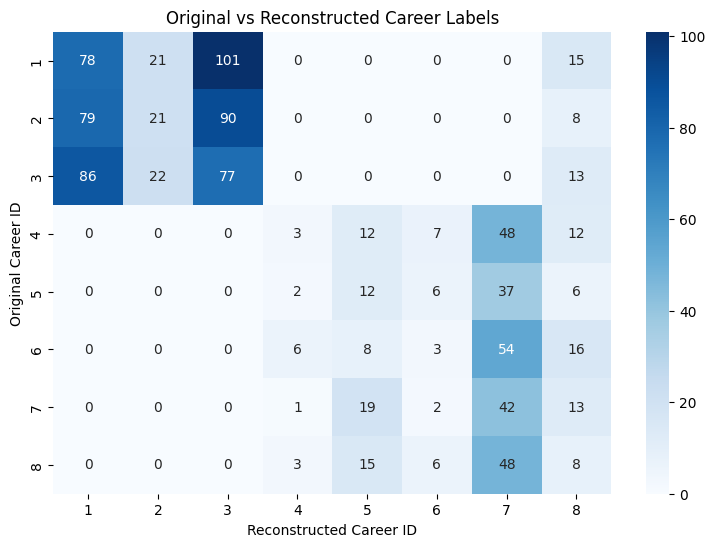

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    comparison["actual_career_id"],
    comparison["reconstructed_career_id"],
    labels=range(1, 9)
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(1, 9),
    yticklabels=range(1, 9)
)

plt.xlabel("Reconstructed Career ID")
plt.ylabel("Original Career ID")
plt.title("Original vs Reconstructed Career Labels")

plt.show()

In [ ]:
mismatches = rule_data[
    rule_data["actual_career_id"] !=
    rule_data["reconstructed_career_id"]
]

display(mismatches.head(15))

,student_id,class,actual_career_id,avg_academic_score,avg_extra_score,avg_sports_score,academic_activity_count,extra_activity_count,sports_activity_count,reconstructed_career_id
2,3,11,4,58.000000,70.0,61.0,1.0,2.0,2.0,7
3,4,12,4,82.000000,54.0,72.5,1.0,1.0,2.0,7
4,5,9,1,59.500000,68.0,76.5,2.0,1.0,2.0,8
5,6,9,2,89.500000,0.0,47.0,2.0,0.0,1.0,1
6,7,11,7,89.000000,0.0,75.5,2.0,0.0,2.0,8
8,9,9,1,60.000000,0.0,47.0,1.0,0.0,1.0,3
10,11,11,8,74.500000,88.0,0.0,2.0,1.0,0.0,7
11,12,9,3,68.000000,89.0,0.0,2.0,1.0,0.0,2
12,13,11,4,86.500000,53.0,90.0,2.0,1.0,1.0,8
14,15,11,4,63.500000,82.0,66.0,2.0,1.0,2.0,7


In [ ]:
print("Original labels:")
print(student["actual_career_id"].value_counts().sort_index())

print("\nReconstructed labels:")
print(rule_data["reconstructed_career_id"].value_counts().sort_index())

Original labels:
actual_career_id
1    215
2    198
3    198
4     82
5     63
6     87
7     77
8     80
Name: count, dtype: int64

Reconstructed labels:
reconstructed_career_id
1    243
2     64
3    268
4     15
5     66
6     24
7    229
8     91
Name: count, dtype: int64


In [ ]:
class_agreement = (
    rule_data.groupby("class")
    .apply(
        lambda group: (
            group["actual_career_id"] ==
            group["reconstructed_career_id"]
        ).mean(),
        include_groups=False
    )
    .reset_index(name="agreement")
)

class_agreement["agreement"] *= 100

display(class_agreement)

,class,agreement
0,8,31.413613
1,9,27.272727
2,10,27.927928
3,11,19.072165
4,12,15.897436


In [ ]:
!cat Student-Career-Prediction-System/code/train_model.py

import mysql.connector
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import joblib

MODEL_PATH = "career_model.pkl"

# ---------------- DB CONNECTION ----------------
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="user123",
    database="career_path_db"
)

print("Connected to DB")

# ---------------- LOAD DATA ----------------
features_df = pd.read_sql("SELECT * FROM student_features_v2", conn)

labels_df = pd.read_sql("""
    SELECT student_id, actual_career_id
    FROM Student
    WHERE actual_career_id IS NOT NULL
""", conn)

data = features_df.merge(labels_df, on="student_id")

# Handle nulls
data["avg_academic_score"] = data["avg_academic_score"].fillna(0)
data["avg_sports_score"] = data["avg_sports_score"].fillna(0)
data["avg_extra_score"] = data["avg_extra_score"].fillna(0)

# ---------------- FEATURES ----------------
X = da

In [ ]:
!cat Student-Career-Prediction-System/code/predict_new_students.py

import mysql.connector
import pandas as pd
import joblib
import sys

MODEL_PATH = "career_model.pkl"

# ---------------- DB CONNECTION ----------------
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="user123",
    database="career_path_db"
)

print("Connected to DB")

# ---------------- LOAD MODEL ----------------
model = joblib.load(MODEL_PATH)
print("Model loaded")

# ---------------- LOAD FEATURES ----------------
features_df = pd.read_sql("SELECT * FROM student_features_v2", conn)

# ---------------- FILTER NEW STUDENTS ----------------
students_df = pd.read_sql("""
    SELECT student_id
    FROM Student
    WHERE predicted_career_id IS NULL
""", conn)

if students_df.empty:
    print("No new students to predict")
    conn.close()
    sys.exit()

# Merge features
data = features_df.merge(students_df, on="student_id")

# Handle nulls
data["avg_academic_score"] = data["avg_academic_score"].fillna(0)
data["avg_sports_score"] = data["avg_sports_scor

In [ ]:
DecisionTreeClassifier(
    max_depth=6,
    random_state=42
)

DecisionTreeClassifier(max_depth=6, random_state=42)

In [ ]:
# Calculate total activities
total_activity = (
    activity.groupby("student_id")
    .size()
    .reset_index(name="total_activities")
)

# Prepare original model features
original_data = student[
    ["student_id", "class", "actual_career_id"]
].merge(
    rule_features,
    on="student_id",
    how="left"
)

original_data = original_data.merge(
    total_activity,
    on="student_id",
    how="left"
)

original_data = original_data.fillna(0)

original_features = [
    "class",
    "avg_academic_score",
    "avg_sports_score",
    "avg_extra_score",
    "academic_activity_count",
    "sports_activity_count",
    "extra_activity_count",
    "total_activities"
]

X_original = original_data[original_features]
y_original = original_data["actual_career_id"]

print("Original feature dataset:", X_original.shape)
display(X_original.head())

Original feature dataset: (1000, 8)


,class,avg_academic_score,avg_sports_score,avg_extra_score,academic_activity_count,sports_activity_count,extra_activity_count,total_activities
0,9,82.0,0.0,57.0,4.0,0.0,1.0,5
1,8,57.5,0.0,0.0,2.0,0.0,0.0,2
2,11,58.0,61.0,70.0,1.0,2.0,2.0,5
3,12,82.0,72.5,54.0,1.0,2.0,1.0,4
4,9,59.5,76.5,68.0,2.0,2.0,1.0,5


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

X_train_original, X_test_original, y_train_original, y_test_original = train_test_split(
    X_original,
    y_original,
    test_size=0.2,
    random_state=42
)

original_model = DecisionTreeClassifier(
    max_depth=6,
    random_state=42
)

original_model.fit(X_train_original, y_train_original)

original_train_pred = original_model.predict(X_train_original)
original_test_pred = original_model.predict(X_test_original)

print("Original Model Training Accuracy:",
      f"{accuracy_score(y_train_original, original_train_pred):.2%}")

print("Original Model Testing Accuracy:",
      f"{accuracy_score(y_test_original, original_test_pred):.2%}")

print("\nClassification Report:")

print(classification_report(
    y_test_original,
    original_test_pred,
    zero_division=0
))

Original Model Training Accuracy: 44.38%
Original Model Testing Accuracy: 29.50%

Classification Report:
              precision    recall  f1-score   support

           1       0.41      0.48      0.44        46
           2       0.33      0.41      0.37        44
           3       0.50      0.25      0.33        36
           4       0.00      0.00      0.00        16
           5       0.00      0.00      0.00         9
           6       0.07      0.05      0.06        20
           7       0.40      0.14      0.21        14
           8       0.17      0.47      0.25        15

    accuracy                           0.29       200
   macro avg       0.24      0.22      0.21       200
weighted avg       0.30      0.29      0.28       200



In [ ]:
comparison_results = pd.DataFrame({
    "Model": [
        "Our Decision Tree",
        "Original Configuration"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test_original, original_test_pred)
    ]
})

print(comparison_results.to_string(index=False))

                 Model  Accuracy
     Our Decision Tree     0.310
Original Configuration     0.295


In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

# Verify that both datasets have students in the same order
assert (
    ml_data["student_id"].values ==
    original_data["student_id"].values
).all(), "Student order mismatch!"

# Create common indices
indices = np.arange(len(y))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 15-feature dataset
X15_train = X.iloc[train_idx]
X15_test = X.iloc[test_idx]

# Original 8-feature dataset
X8_train = X_original.iloc[train_idx]
X8_test = X_original.iloc[test_idx]

y_train_common = y.iloc[train_idx]
y_test_common = y.iloc[test_idx]

print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))

Training samples: 800
Testing samples: 200


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Decision Tree (8 features)": DecisionTreeClassifier(
        max_depth=6,
        random_state=42
    ),

    "Decision Tree (15 features)": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42
    )
}

comparison = []

for name, model in models.items():

    if "8 features" in name:
        model.fit(X8_train, y_train_common)
        predictions = model.predict(X8_test)

    else:
        model.fit(X15_train, y_train_common)
        predictions = model.predict(X15_test)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_test_common, predictions
        ),
        "Macro F1": f1_score(
            y_test_common,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test_common,
            predictions,
            average="weighted",
            zero_division=0
        )
    })

fair_results = pd.DataFrame(comparison)

display(fair_results.round(4))

,Model,Accuracy,Macro F1,Weighted F1
0,Decision Tree (8 features),0.365,0.2792,0.3305
1,Decision Tree (15 features),0.310,0.2642,0.3041
2,Logistic Regression,0.305,0.2529,0.2982
3,Random Forest,0.300,0.2455,0.2976


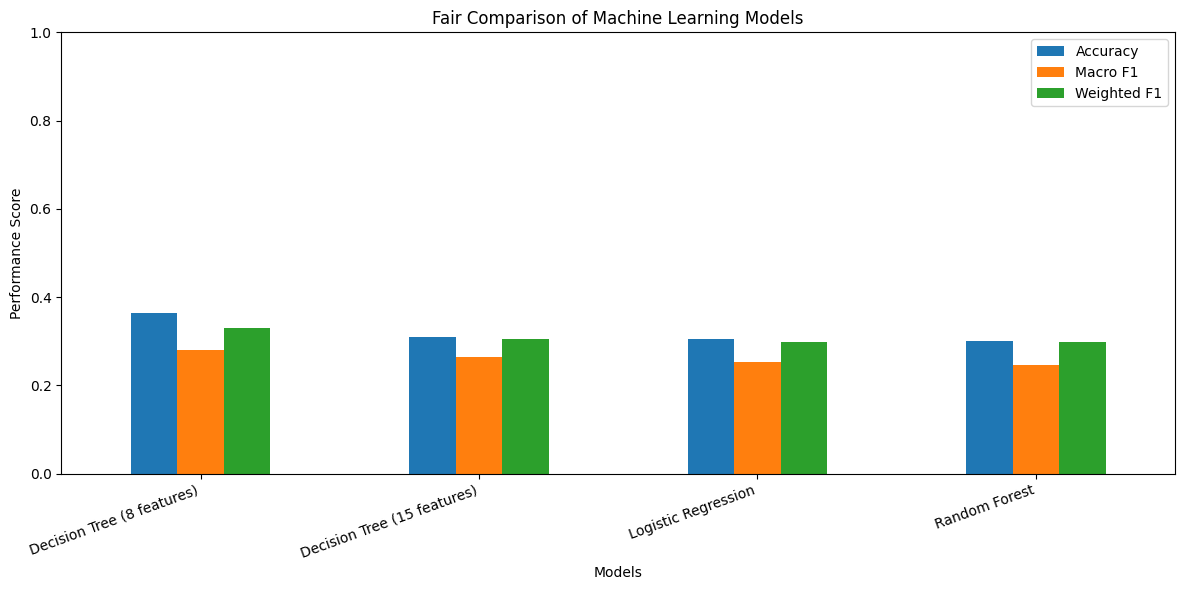

In [ ]:
fair_results.set_index("Model")[
    ["Accuracy", "Macro F1", "Weighted F1"]
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("Fair Comparison of Machine Learning Models")
plt.ylabel("Performance Score")
plt.xlabel("Models")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

dt_params = {
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "class_weight": [None, "balanced"]
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_params,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

dt_grid.fit(X8_train, y_train_common)

print("Best Parameters:")
print(dt_grid.best_params_)

print("\nBest Cross-validation Macro F1:")
print(dt_grid.best_score_)

Best Parameters:
{'class_weight': None, 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}

Best Cross-validation Macro F1:
0.28002682701211434


In [ ]:
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

lr_params = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
    "model__solver": ["lbfgs"]
}

lr_grid = GridSearchCV(
    lr_pipeline,
    lr_params,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

lr_grid.fit(X15_train, y_train_common)

print("Best Parameters:")
print(lr_grid.best_params_)

print("\nBest Cross-validation Macro F1:")
print(lr_grid.best_score_)

Best Parameters:
{'model__C': 0.1, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}

Best Cross-validation Macro F1:
0.26836764877763936
